In [ ]:
import os, re, random, time, copy, urllib.parse
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

smoke_test = os.environ.get("SMOKE_TEST") == "1"
data_dir = os.environ.get("DATA_DIR", "Web-Application-Attack-Datasets/OriginalDataSets/csic_2010")

max_len = 512
n_embd, n_head, n_layer, dropout = 128, 4, 4, 0.2
batch_size, iters, lr = 64, 6000, 3e-4
if smoke_test:
    n_embd, n_head, n_layer, batch_size, iters = 32, 2, 2, 32, 150
if os.environ.get("MID") == "1":
    n_embd, n_head, n_layer, batch_size, iters = 96, 4, 3, 32, 2000

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337); random.seed(1337); np.random.seed(1337)

In [ ]:
if not os.path.exists(data_dir):
    os.system("git clone -q --depth 1 https://github.com/msudol/Web-Application-Attack-Datasets.git")

In [3]:
num_re = re.compile(r"\d+")

def load_requests(path):
    reqs, cur, body_next = [], None, False
    for raw in open(path, encoding="latin-1"):
        line = raw.rstrip("\r\n")
        m = re.match(r"^(GET|POST|PUT) (\S+) HTTP", line)
        if m:
            if cur: reqs.append(cur)
            cur = {"method": m.group(1), "url": m.group(2), "body": ""}; body_next = False
            continue
        if cur is None: continue
        if line.startswith("Content-Length"):
            body_next = True; continue
        if body_next and line and ":" not in line[:20]:
            cur["body"] = line; body_next = False
    if cur: reqs.append(cur)
    out = []
    for r in reqs:
        u = r["url"].replace("http://localhost:8080", "")
        if r["body"]:
            u += ("&" if "?" in u else "?") + r["body"]
        s = urllib.parse.unquote_plus(r["method"] + " " + u, encoding="latin-1")
        s = num_re.sub("0", s)
        s = re.sub(r"[\r\n\t]", " ", s)
        out.append(s[:max_len])
    return out

normal_train = load_requests(f"{data_dir}/normalTrafficTraining.txt")
normal_test  = load_requests(f"{data_dir}/normalTrafficTest.txt")
attack_test  = load_requests(f"{data_dir}/anomalousTrafficTest.txt")
print(f"normal eğitim {len(normal_train):,} (eşsiz {len(set(normal_train)):,})")
print(f"normal test   {len(normal_test):,} (eşsiz {len(set(normal_test)):,})")
print(f"saldırı test  {len(attack_test):,} (eşsiz {len(set(attack_test)):,})")
for s in normal_train[:3]: print("  N:", s[:120])
for s in random.sample(attack_test, 3): print("  A:", s[:120])

normal eğitim 36,000 (eşsiz 6,034)
normal test   36,000 (eşsiz 6,034)
saldırı test  25,065 (eşsiz 11,744)
  N: GET /tienda0/index.jsp
  N: GET /tienda0/publico/anadir.jsp?id=0&nombre=Vino Rioja&precio=0&cantidad=0&B0=Añadir al carrito
  N: POST /tienda0/publico/anadir.jsp?id=0&nombre=Vino Rioja&precio=0&cantidad=0&B0=Añadir al carrito
  A: POST /tienda0/publico/caracteristicas.jsp?id=0any%0ASet-cookie%0A+Tamper%0D0
  A: POST /tienda0/publico/entrar.jsp?errorMsgA=Credenciales incorrectas
  A: GET /tienda0/publico/caracteristicas.jsp?id=0'OR'a='a


In [4]:
uniq_train = sorted(set(normal_train)); random.shuffle(uniq_train)
k = int(.9 * len(uniq_train))
train_lines, val_lines = uniq_train[:k], uniq_train[k:]
train_set = set(train_lines)

test_norm = sorted(set(normal_test))
test_att  = sorted(set(attack_test) - set(normal_test))
test_lines = test_norm + test_att
test_y = np.array([0]*len(test_norm) + [1]*len(test_att))
seen = np.array([s in train_set for s in test_lines])
print(f"train {len(train_lines):,} | val {len(val_lines):,} | test normal {len(test_norm):,} + saldırı {len(test_att):,}")
print(f"test normal isteklerin eğitimde birebir görülme oranı: {seen[test_y==0].mean():.1%}")
print(f"saldırı isteklerinin eğitimde görülme oranı: {seen[test_y==1].mean():.1%}")

train 5,430 | val 604 | test normal 6,034 + saldırı 11,744
test normal isteklerin eğitimde birebir görülme oranı: 0.4%
saldırı isteklerinin eğitimde görülme oranı: 0.0%


In [5]:
chars = sorted(set("".join(train_lines)))
pad, bos, eos = 0, 1, 2
stoi = {c: i+3 for i, c in enumerate(chars)}
unk = len(stoi) + 3 # eğitimde hiç görülmemiş karakter
vocab_size = unk + 1
seq_len = max_len + 2
print("vocab:", vocab_size)

def encode(lines):
    x_ids = torch.full((len(lines), seq_len), pad, dtype=torch.long)
    for i, s in enumerate(lines):
        ids = [bos] + [stoi.get(c, unk) for c in s] + [eos]
        x_ids[i, :len(ids)] = torch.tensor(ids)
    return x_ids

xtr, xva, xte = encode(train_lines), encode(val_lines), encode(test_lines)

vocab: 98


In [6]:
class Head(nn.Module):
    def __init__(self, hs):
        super().__init__()
        self.key = nn.Linear(n_embd, hs, bias=False)
        self.query = nn.Linear(n_embd, hs, bias=False)
        self.value = nn.Linear(n_embd, hs, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(seq_len, seq_len)))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        b, t, c = x.shape
        k, q, v = self.key(x), self.query(x), self.value(x)
        w = q @ k.transpose(-2, -1) * k.shape[-1]**-0.5
        w = w.masked_fill(self.tril[:t, :t] == 0, float("-inf"))
        return self.drop(F.softmax(w, dim=-1)) @ v

class MultiHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.heads = nn.ModuleList([Head(n_embd // n_head) for _ in range(n_head)])
        self.proj = nn.Linear(n_embd, n_embd)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        return self.drop(self.proj(torch.cat([h(x) for h in self.heads], dim=-1)))

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.sa = MultiHead()
        self.ff = nn.Sequential(nn.Linear(n_embd, 4*n_embd), nn.GELU(),
                                nn.Linear(4*n_embd, n_embd), nn.Dropout(dropout))
        self.ln1, self.ln2 = nn.LayerNorm(n_embd), nn.LayerNorm(n_embd)
    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        return x + self.ff(self.ln2(x))

class CharGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, n_embd)
        self.pos = nn.Embedding(seq_len, n_embd)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size)
    def forward(self, idx):
        t = idx.shape[1]
        x = self.tok(idx) + self.pos(torch.arange(t, device=idx.device))
        return self.head(self.ln(self.blocks(x)))

def char_nll(model, x_ids):
    L = int((x_ids != pad).sum(1).max())
    x_ids = x_ids[:, :L]
    logits = model(x_ids[:, :-1])
    tgt = x_ids[:, 1:]
    nll = F.cross_entropy(logits.reshape(-1, vocab_size), tgt.reshape(-1),
                          ignore_index=pad, reduction="none").view(tgt.shape)
    return nll, (tgt != pad)

model = CharGPT().to(device)
print(f"parametre: {sum(p.numel() for p in model.parameters()):,}")

parametre: 882,786


In [7]:
opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
hist = {"it": [], "train": [], "val": []}

@torch.no_grad()
def full_loss(x_ids, bs=256):
    model.eval(); tot = cnt = 0
    for i in range(0, len(x_ids), bs):
        nll, m = char_nll(model, x_ids[i:i+bs].to(device))
        tot += (nll*m).sum().item(); cnt += m.sum().item()
    model.train(); return tot / cnt

best_val, best_state, best_it = float("inf"), None, 0
t0 = time.time()
for it in range(iters + 1):
    xb = xtr[torch.randint(len(xtr), (batch_size,))].to(device)
    nll, m = char_nll(model, xb)
    loss = (nll*m).sum() / m.sum()
    opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    if it % max(1, iters//20) == 0:
        tl, vl = full_loss(xtr[:2000]), full_loss(xva)
        hist["it"].append(it); hist["train"].append(tl); hist["val"].append(vl)
        if vl < best_val:
            best_val, best_it, best_state = vl, it, copy.deepcopy(model.state_dict())
        print(f"it {it:5d} | train {tl:.4f} | val {vl:.4f} | {time.time()-t0:.0f}s")

model.load_state_dict(best_state)
print(f"en iyi val: {best_val:.4f} (it {best_it}) -> bu model kullanılacak")

it     0 | train 4.6171 | val 4.6183 | 2s
it   300 | train 1.3055 | val 1.3096 | 32s
it   600 | train 1.0296 | val 1.0373 | 63s
it   900 | train 0.9579 | val 0.9683 | 95s
it  1200 | train 0.9268 | val 0.9393 | 128s
it  1500 | train 0.9050 | val 0.9191 | 159s
it  1800 | train 0.8869 | val 0.9037 | 192s
it  2100 | train 0.8680 | val 0.8879 | 227s
it  2400 | train 0.8512 | val 0.8730 | 261s
it  2700 | train 0.8384 | val 0.8619 | 296s
it  3000 | train 0.8274 | val 0.8558 | 330s
it  3300 | train 0.8177 | val 0.8459 | 365s
it  3600 | train 0.8082 | val 0.8404 | 399s
it  3900 | train 0.8003 | val 0.8353 | 434s
it  4200 | train 0.7928 | val 0.8306 | 469s
it  4500 | train 0.7850 | val 0.8259 | 503s
it  4800 | train 0.7783 | val 0.8220 | 538s
it  5100 | train 0.7722 | val 0.8194 | 573s
it  5400 | train 0.7638 | val 0.8163 | 607s
it  5700 | train 0.7564 | val 0.8130 | 642s
it  6000 | train 0.7503 | val 0.8103 | 677s
en iyi val: 0.8103 (it 6000) -> bu model kullanılacak


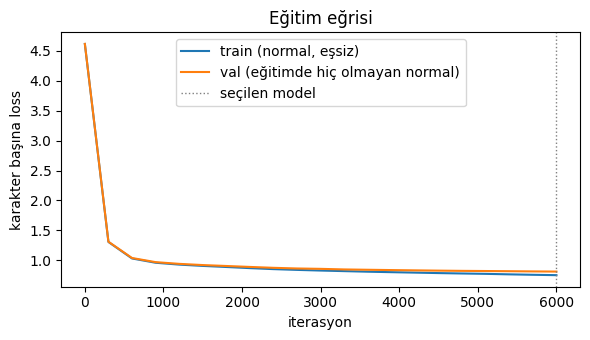

In [8]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,3.5))
plt.plot(hist["it"], hist["train"], label="train (normal, eşsiz)")
plt.plot(hist["it"], hist["val"], label="val (eğitimde hiç olmayan normal)")
plt.axvline(best_it, color="gray", ls=":", lw=1, label="seçilen model")
plt.xlabel("iterasyon"); plt.ylabel("karakter başına loss"); plt.title("Eğitim eğrisi")
plt.legend(); plt.tight_layout(); plt.savefig("loss_curve.png", dpi=150); plt.show()

In [9]:
@torch.no_grad()
def score_lines(x_ids, bs=256):
    model.eval(); mean_out, max_out = [], []
    for i in range(0, len(x_ids), bs):
        nll, m = char_nll(model, x_ids[i:i+bs].to(device))
        mean_out.append(((nll*m).sum(1) / m.sum(1)).cpu())
        max_out.append((nll*m).max(1).values.cpu())
    return torch.cat(mean_out).numpy(), torch.cat(max_out).numpy()

val_mean, val_max = score_lines(xva)
test_mean, test_max = score_lines(xte)
th_mean, th_max = np.percentile(val_mean, 99), np.percentile(val_max, 99)
print(f"eşik ort {th_mean:.3f} | eşik max {th_max:.3f}")

eşik ort 1.177 | eşik max 10.471


In [10]:
counts = torch.ones(vocab_size, vocab_size)
for i in range(len(xtr)):
    row = xtr[i]; L = int((row != pad).sum())
    counts.index_put_((row[:L-1], row[1:L]), torch.ones(L-1), accumulate=True)
logP = (counts / counts.sum(1, keepdim=True)).log()

def bigram_scores(x_ids):
    a, b = x_ids[:, :-1], x_ids[:, 1:]
    m = (b != pad).float()
    return ((-logP[a, b]) * m).sum(1).div(m.sum(1)).numpy()

bg_val, bg_test = bigram_scores(xva), bigram_scores(xte)
th_bg = np.percentile(bg_val, 99)
ezber = (~seen).astype(float)

In [11]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score

def report_on(name, s, th, mask):
    y, sc = test_y[mask], s[mask]
    pred = (sc > th).astype(int)
    auc = roc_auc_score(y, sc) if 0 < y.sum() < len(y) else float("nan")
    return dict(model=name, auc=auc,
                precision=precision_score(y, pred, zero_division=0),
                recall=recall_score(y, pred, zero_division=0),
                fpr=pred[y==0].mean() if (y==0).any() else float("nan"))

def print_table(rs):
    print(f"{'model':10s} {'ROC-AUC':>8s} {'precision':>10s} {'recall':>8s} {'yanlış alarm':>13s}")
    for r in rs:
        print(f"{r['model']:10s} {r['auc']:8.4f} {r['precision']:10.3f} {r['recall']:8.3f} {r['fpr']:13.3%}")

all_mask, unseen = np.ones(len(test_y), bool), ~seen
scores = [("Ezber", ezber, 0.5), ("Bigram", bg_test, th_bg),
          ("GPT-ort", test_mean, th_mean), ("GPT-max", test_max, th_max)]
print(f"TÜM TEST (eşsiz): normal {(test_y==0).sum():,}, saldırı {(test_y==1).sum():,}")
print_table([report_on(n_, s_, t_, all_mask) for n_, s_, t_ in scores])
print(f"\nSADECE EĞİTİMDE GÖRÜLMEMİŞ: normal {(unseen & (test_y==0)).sum():,}, saldırı {(unseen & (test_y==1)).sum():,}")
print_table([report_on(n_, s_, t_, unseen) for n_, s_, t_ in scores[1:]])

TÜM TEST (eşsiz): normal 6,034, saldırı 11,744
model       ROC-AUC  precision   recall  yanlış alarm
Ezber        0.5022      0.662    1.000       99.569%
Bigram       0.7874      0.991    0.422        0.729%
GPT-ort      0.8492      0.994    0.471        0.563%
GPT-max      0.9905      0.985    0.952        2.801%

SADECE EĞİTİMDE GÖRÜLMEMİŞ: normal 6,008, saldırı 11,744
model       ROC-AUC  precision   recall  yanlış alarm
Bigram       0.7882      0.993    0.422        0.566%
GPT-ort      0.8496      0.995    0.471        0.499%
GPT-max      0.9907      0.986    0.952        2.696%


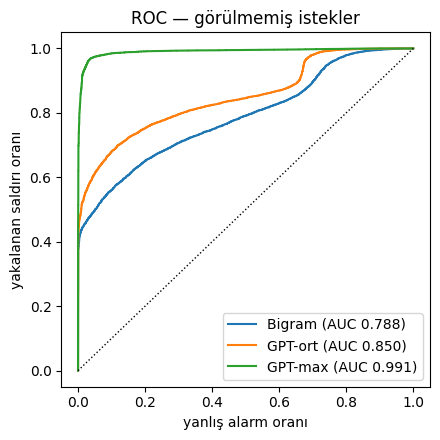

In [12]:
from sklearn.metrics import roc_curve
plt.figure(figsize=(4.5,4.5))
for name, s in [("Bigram", bg_test), ("GPT-ort", test_mean), ("GPT-max", test_max)]:
    fpr, tpr, _ = roc_curve(test_y[unseen], s[unseen])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test_y[unseen], s[unseen]):.3f})")
plt.plot([0,1], [0,1], "k:", lw=1)
plt.xlabel("yanlış alarm oranı"); plt.ylabel("yakalanan saldırı oranı")
plt.title("ROC — görülmemiş istekler"); plt.legend(); plt.tight_layout()
plt.savefig("roc_unseen.png", dpi=150); plt.show()

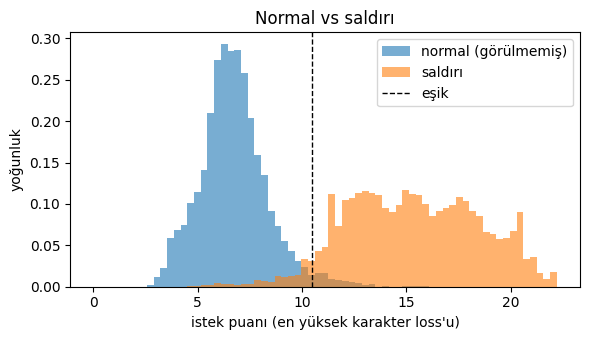

In [13]:
plt.figure(figsize=(6,3.5))
bins = np.linspace(0, np.percentile(test_max, 99.5), 70)
plt.hist(test_max[(test_y==0) & unseen], bins=bins, alpha=.6, label="normal (görülmemiş)", density=True)
plt.hist(test_max[test_y==1], bins=bins, alpha=.6, label="saldırı", density=True)
plt.axvline(th_max, color="k", ls="--", lw=1, label="eşik")
plt.xlabel("istek puanı (en yüksek karakter loss'u)"); plt.ylabel("yoğunluk")
plt.title("Normal vs saldırı"); plt.legend(); plt.tight_layout()
plt.savefig("score_hist.png", dpi=150); plt.show()

In [14]:
# En şüpheli istekler, yanlış alarmlar ve kaçırılan saldırılar (GPT-max)
order = np.argsort(-test_max)
print("EN ŞÜPHELİ 10 İSTEK")
for i in order[:10]:
    print(f"{test_max[i]:5.2f} [{'SALDIRI' if test_y[i] else 'normal '}] {test_lines[i][:110]}")
print("\nYANLIŞ ALARM (normal ama eşiğin üstünde)")
for i in [i for i in order if test_y[i]==0 and test_max[i] > th_max][:8]:
    print(f"{test_max[i]:5.2f} {test_lines[i][:110]}")
print("\nKAÇIRILAN SALDIRI (eşiğin altında, en düşük puanlılar)")
for i in [i for i in order[::-1] if test_y[i]==1 and test_max[i] <= th_max][:8]:
    print(f"{test_max[i]:5.2f} {test_lines[i][:110]}")

EN ŞÜPHELİ 10 İSTEK
23.37 [SALDIRI] POST /tienda0/miembros/editar.jsp?modo=registro&login=knobloch0&password=B0i0a&nombre=Nahuel&apellidos=Arbona 
23.32 [SALDIRI] GET /tienda0/miembros/editar.jsp?modo=registro&login=schwenk&password=iNfINitIvO&nombre=Tarciano&apellidos=Var
23.29 [SALDIRI] GET /tienda0/publico/registro.jsp?modo=registro&login=maher&password=ca0alo&nombre=Indira&apellidos=Ludeñas Lo
23.20 [SALDIRI] GET /tienda0/miembros/editar.jsp?modo=registro&login=vassilik&password=d0sc0r0AN0&nombre=Adelmo&apellidos=Capa
23.18 [SALDIRI] POST /tienda0/publico/registro.jsp?modo=registro&login=marymarg&password=r0E0&nombre=Ronnie&apellidos=Puigferr
23.11 [SALDIRI] POST /tienda0/publico/registro.jsp?modo=registro&login=student&password=ali0ra&nombre=Jaled&apellidos=Miralles
23.11 [SALDIRI] POST /tienda0/publico/registro.jsp?modo=registro&login=bagnato0&password=prescindible&nombre=Hiram&apellidos=P
23.06 [SALDIRI] POST /tienda0/miembros/editar.jsp?modo=registro&login=vassilik&password=d0s

In [15]:
# Saldırı türüne göre kaba ayrım ve yakalanma oranı
def attack_type(s):
    t = s.lower()
    if "<script" in t or "alert(" in t or "javascript:" in t: return "XSS"
    if re.search(r"'|--|\bor\b.*=|union|select|drop ", t): return "SQL injection"
    if "../" in t or "etc/passwd" in t: return "path traversal"
    if re.search(r"\.(bak|old|inc|htr|cgi|exe|ini|conf)\b", t): return "gizli dosya arama"
    return "diğer (parametre kurcalama vb.)"
from collections import defaultdict
d = defaultdict(lambda: [0, 0])
for i in np.where(test_y==1)[0]:
    c = attack_type(test_lines[i]); d[c][0] += test_max[i] > th_max; d[c][1] += 1
print("saldırı türü                     yakalanan / toplam")
for c, (a, b) in sorted(d.items(), key=lambda kv: -kv[1][1]):
    print(f"{c:32s} {a:6d} / {b:<6d} ({a/b:.0%})")

saldırı türü                     yakalanan / toplam
diğer (parametre kurcalama vb.)    7590 / 8084   (94%)
SQL injection                      2204 / 2237   (99%)
gizli dosya arama                   943 / 979    (96%)
XSS                                 444 / 444    (100%)


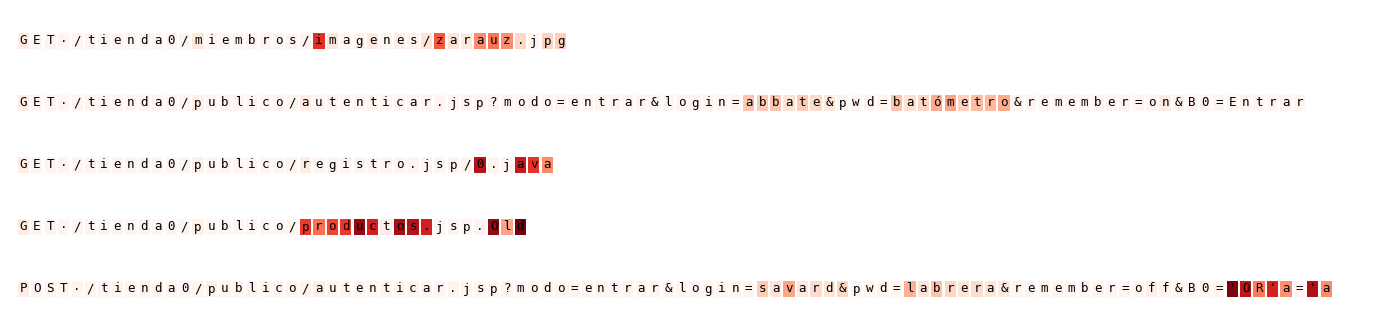

In [16]:
@torch.no_grad()
def per_char(line):
    model.eval()
    nll, m = char_nll(model, encode([line]).to(device))
    return nll[0, :len(line)].cpu().numpy()

def draw_lines(lines, fname="heatmap.png", width=100, vmax=None):
    vals = [per_char(l[:width]) for l in lines]
    vmax = vmax or max(np.percentile(np.concatenate(vals), 99), 1.0)
    fig, ax = plt.subplots(figsize=(14, 0.6*len(lines)+0.4))
    ax.axis("off"); cmap = plt.get_cmap("Reds")
    for r, (line, v) in enumerate(zip(lines, vals)):
        for c, ch in enumerate(line[:width]):
            ax.text(c, -r, ch if ch != " " else "·", family="monospace", fontsize=9, ha="center", va="center",
                    bbox=dict(boxstyle="square,pad=0.15", fc=cmap(min(v[c]/vmax, 1)), ec="none"))
    ax.set_xlim(-1, width+1); ax.set_ylim(-len(lines)+0.5, 0.5)
    plt.tight_layout(); plt.savefig(fname, dpi=150, bbox_inches="tight"); plt.show()

norm_ex = [test_lines[i] for i in np.where((test_y==0) & unseen)[0]
           if 40 < len(test_lines[i]) < 100 and test_max[i] < th_max][:2]
ex, used = [], set()
for i in order:
    c = attack_type(test_lines[i])
    if test_y[i] and c not in used and len(test_lines[i]) < 100:
        used.add(c); ex.append(test_lines[i])
    if len(ex) == 3: break
draw_lines(norm_ex + ex)

In [ ]:
torch.save({"model": model.state_dict(), "stoi": stoi}, "char_gpt_csic.pt")